In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/sample_data/Supermarket Sales Analysis Dashboard (V.2).csv')
df.head(5)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [ ]:
df.shape

(8523, 12)

In [ ]:
print(df.isnull().sum())

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [ ]:
df.dropna(inplace=True)

In [ ]:
print(df.isnull().sum())

Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


In [ ]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,7060.000000,7060.000000,7060.000000,7060.000000,7060.000000
mean,2016.129462,0.063963,12.857645,141.240685,3.965382
std,3.417571,0.048625,4.643456,62.411888,0.610523
min,2011.000000,0.000000,4.555000,31.490000,1.000000
25%,2014.000000,0.026768,8.773750,94.143600,4.000000
50%,2016.000000,0.052493,12.600000,142.729900,4.000000
75%,2020.000000,0.092774,16.850000,186.024000,4.200000
max,2022.000000,0.311090,21.350000,266.888400,5.000000


# TASK 1
To evaluate the supermarket's overall business performance and understand its key sales metrics.

In [ ]:
#total sales revenue of supermarket
print(sum(df['Sales']))

997159.2358


In [ ]:
#average sales value per record
avg_sales=sum(df['Sales'])/len(df['Sales'])
print(avg_sales)

141.24068495750709


In [ ]:
#average visibility of products across the supermarket
avg_visibility=sum(df['Rating'])/len(df['Rating'])
print(avg_visibility)

3.965382436260623


# TASK 2
To analyze product category sales contributions and identify the highest- and lowest-performing categories and outlets.

In [ ]:
#percentage of total sales is contributed by the top four product categories compared with all remaining categories
print(df.groupby('Item Type')['Sales'].sum().nlargest(4).sum()/df['Sales'].sum()*100)

50.67496733303586


In [ ]:
#product categories generate the highest and lowest total sales
print(df.groupby('Item Type')['Sales'].sum().nlargest(1))
print(df.groupby('Item Type')['Sales'].sum().nsmallest())

Item Type
Fruits and Vegetables    147188.9632
Name: Sales, dtype: float64
Item Type
Seafood           7397.5644
Breakfast        12696.1874
Others           18624.5970
Starchy Foods    19199.9772
Hard Drinks      25261.6214
Name: Sales, dtype: float64


In [ ]:
#total sales compare across different outlet types
print(df.groupby('Outlet Type')['Sales'].sum())

Outlet Type
Grocery Store         78131.5666
Supermarket Type1    787549.8928
Supermarket Type2    131477.7764
Name: Sales, dtype: float64


In [ ]:
df.head(4)

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0


In [ ]:
#To compare outlet sales performance and understand the relationship between product visibility and sales.
print(df.groupby('Outlet Type')['Item Visibility'].sum())

Outlet Type
Grocery Store         56.308832
Supermarket Type1    338.651294
Supermarket Type2     56.621455
Name: Item Visibility, dtype: float64


<Axes: xlabel='Item Visibility', ylabel='Sales'>

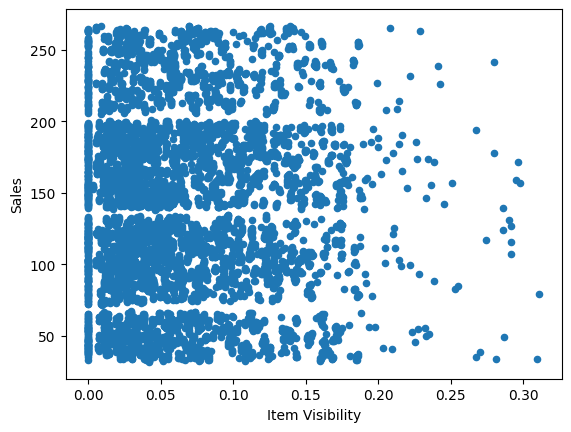

In [ ]:
df.plot(kind='scatter',x='Item Visibility',y='Sales')

Interpretation:

# TASK 3
To compare outlet sales performance and understand the relationship between product visibility and sales.

In [ ]:
#How do sales vary across outlets for Low Fat and Regular products?
print(df.groupby(['Outlet Type','Item Type'])['Sales'].sum())

Outlet Type        Item Type            
Grocery Store      Baking Goods               5328.4502
                   Breads                     2632.9732
                   Breakfast                  1510.9266
                   Canned                     4551.2196
                   Dairy                      6707.8582
                   Frozen Foods               7359.7874
                   Fruits and Vegetables     10789.6834
                   Hard Drinks                2041.7454
                   Health and Hygiene         4993.1316
                   Household                  9822.0842
                   Meat                       4624.2074
                   Others                     1241.6564
                   Seafood                     626.0546
                   Snack Foods               10649.7554
                   Soft Drinks                4002.9870
                   Starchy Foods              1249.0460
Supermarket Type1  Baking Goods              53665.4614
       

In [ ]:
#How do sales contributions from different product categories vary across outlet types?
print(df.groupby(['Outlet Type','Item Type'])['Sales'].sum()/df.groupby('Outlet Type')['Sales'].sum()*100)

Outlet Type        Item Type            
Grocery Store      Baking Goods              6.819843
                   Breads                    3.369922
                   Breakfast                 1.933824
                   Canned                    5.825071
                   Dairy                     8.585337
                   Frozen Foods              9.419736
                   Fruits and Vegetables    13.809634
                   Hard Drinks               2.613214
                   Health and Hygiene        6.390671
                   Household                12.571211
                   Meat                      5.918488
                   Others                    1.589187
                   Seafood                   0.801283
                   Snack Foods              13.630541
                   Soft Drinks               5.123393
                   Starchy Foods             1.598645
Supermarket Type1  Baking Goods              6.814230
                   Breads                

# TASK 4
To understand sales distribution, variation, and unusual sales values to support better business decisions.

In [ ]:
#average median minimum and maximum sales values
print(df.groupby('Outlet Type')['Sales'].agg(['mean','median','min','max']).round(2))

                     mean  median    min     max
Outlet Type                                     
Grocery Store      140.78  143.91  32.66  266.69
Supermarket Type1  141.21  143.12  31.49  266.89
Supermarket Type2  141.68  140.57  31.89  265.19


In [ ]:
#How much variation exists in sales across product records?
print(df.groupby('Item Type')['Sales'].std().round(2))

Item Type
Baking Goods             58.51
Breads                   63.30
Breakfast                58.70
Canned                   60.93
Dairy                    70.77
Frozen Foods             67.44
Fruits and Vegetables    60.80
Hard Drinks              62.10
Health and Hygiene       58.84
Household                62.42
Meat                     58.07
Others                   58.07
Seafood                  59.27
Snack Foods              58.98
Soft Drinks              60.78
Starchy Foods            70.16
Name: Sales, dtype: float64


In [ ]:
#Which records have unusually high or low sales compared with most records?
print(df.nlargest(5,'Sales'))
print(df.nsmallest(5,'Sales'))

     Item Fat Content Item Identifier           Item Type  \
183           Low Fat           FDS13              Canned   
3398          Regular           FDR25              Canned   
559           Low Fat           FDK51               Dairy   
1775          Low Fat           NCS29  Health and Hygiene   
3563          Low Fat           NCS29  Health and Hygiene   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
183                        2020            OUT017               Tier 2   
3398                       2016            OUT046               Tier 1   
559                        2011            OUT010               Tier 3   
1775                       2014            OUT013               Tier 3   
3563                       2017            OUT035               Tier 2   

     Outlet Size        Outlet Type  Item Visibility  Item Weight     Sales  \
183        Small  Supermarket Type1         0.125210        6.465  266.8884   
3398       Small  Supermarket 

In [ ]:
#How does average sales performance differ across product categories, outlet types, and outlet locations?
print(df.groupby(['Item Type','Outlet Type','Outlet Location Type'])['Sales'].mean())

Item Type      Outlet Type        Outlet Location Type
Baking Goods   Grocery Store      Tier 3                  126.867862
               Supermarket Type1  Tier 1                  123.895787
                                  Tier 2                  126.258343
                                  Tier 3                  129.202044
               Supermarket Type2  Tier 3                  126.385315
                                                             ...    
Starchy Foods  Grocery Store      Tier 3                  138.782889
               Supermarket Type1  Tier 1                  148.197494
                                  Tier 2                  143.834894
                                  Tier 3                  158.157074
               Supermarket Type2  Tier 3                  151.786918
Name: Sales, Length: 80, dtype: float64
